# Sprint 0 — Problem, model and plan

**Project 13: Threshold effects in time-delay tracking: CRLB vs ZZB for DLL and batch MLE for BPSK signals**

This notebook fixes *what* we estimate, *from which data*, and *why every modelling choice was made*. Every later
notebook uses exactly this model, so theory and simulation always describe the same thing.

| Notebook | Sprint | Content | Status |
|---|---|---|---|
| `00_problem_and_model` | 0 | problem, model, notation, literature | done |
| `01_sprint1_batch_mle` | 1 | BPSK signal, batch MLE, first MSE-vs-SNR curve + CRLB | done |
| `02_sprint2_dll` | 2 | early–late DLL: S-curve + tracking run | done |
| `03_sprint3_crlb` | 3 | CRLB derived properly, overlaid on Sprint-1 data | done |
| `04_sprint4_zzb` | 4 | ZZB derived for this case + intuition | done (numerical ZZB already done too, labelled) |
| `05_beyond_sprint4` | 5–6 | 4-curve comparison, threshold study, DLL vs MLE | **already completed / beyond current Sprint 4** |

## 0.1 The question

A transmitter sends a known BPSK waveform $s(t)$. The receiver sees it **delayed by an unknown $\tau$** and buried in
noise, and must estimate $\tau$:

$$ r(t) = s(t-\tau) + w(t). $$

We compare **two estimators** — a *batch maximum-likelihood estimator* (looks at a whole block of data at once) and a
*delay-locked loop* (tracks $\tau$ step by step in real time) — against **two lower bounds** on the error:

* the **Cramér–Rao lower bound (CRLB)**: a *local* bound, accurate at high SNR;
* the **Ziv–Zakai bound (ZZB)**: a *global* (Bayesian) bound that also sees large "wrong-peak" errors.

**The phenomenon of interest — the threshold effect.** At high SNR an estimator's error is small and follows the CRLB.
Below some SNR, noise occasionally makes a *wrong* delay look best, the estimator jumps far away, and the error
explodes. The CRLB cannot predict this; the ZZB is designed to. The project asks: *where is this threshold, does the
ZZB predict it, and why do the DLL and MLE behave differently?*

## 0.2 The model and *why* each choice was made

| Choice | What we use | Why (and what goes wrong otherwise) |
|---|---|---|
| Chips | known pilot $a_k\in\{\pm1\}$, $N_c=64$ chips, random but fixed (seed 2026) | a known pilot ("data-aided") makes the likelihood exact; the same pilot is used by every estimator and bound |
| Pulse | **raised cosine**, roll-off $\alpha=0.5$, truncated to $\lvert t\rvert\le 6$ chips | the CRLB is $1/(2\,\tfrac{E}{N_0}\,\beta^2)$ with $\beta^2$ the signal's mean-square bandwidth. **Rectangular chips have infinite bandwidth → CRLB = 0**, which is meaningless. Real receivers band-limit the signal anyway |
| Sampling | 4 samples/chip | the RC spectrum ends at $(1+\alpha)/2 = 0.75$ cycles/chip, below the Nyquist limit of 2 cycles/chip, so the samples hold all the information |
| Delay | applied **analytically**: we evaluate $s(t_n-\tau)$ directly | no interpolation error, so any discrepancy with theory is real, not numerical |
| Noise | real, white Gaussian, known carrier phase (coherent baseband) | the standard setting in which the CRLB and ZZB have closed forms |
| Prior | $\tau\sim\mathcal U[\tau_c-T_a/2,\ \tau_c+T_a/2]$, $T_a = 4$ chips | the ZZB is a *Bayesian* bound, so it needs a prior. With $T_a=1$ chip (one correlation peak wide) the threshold is *masked*: there is no wrong peak to jump to. $T_a=4$ makes it visible |
| SNR axis | **total batch** $E/N_0$ of the 64-chip pilot (per-chip $E_c/N_0 = E/N_0 - 18.1$ dB) | both bounds depend on the total energy, not the per-sample SNR |
| Error metric | **MSE** $=\mathbb E[(\hat\tau-\tau)^2]$ | below threshold estimators become biased; the ZZB bounds MSE, not variance |

**Relation to the original Sprint-1 script** (`archive/sprint1_original/`). It used a 127-chip m-sequence, a Gaussian
filter, a *fixed* delay and per-sample SNR, and showed the same qualitative result (MLE on the CRLB, then a sharp
break-away). We changed the model because (i) the ZZB needs a *random* delay with a prior, (ii) the bounds are naturally
written in $E/N_0$, and (iii) a raised-cosine pulse has an exactly known spectrum, which makes the CRLB checkable
analytically. The *story* is unchanged.

## 0.3 The mathematics of the model

**Signal.** $\;s(t)=\sum_{k=0}^{N_c-1} a_k\,p(t-k)$, with the raised-cosine pulse

$$ p(t)=\operatorname{sinc}(t)\,\frac{\cos(\pi\alpha t)}{1-(2\alpha t)^2}. $$

$p$ is a **Nyquist pulse**: $p(0)=1$ and $p(k)=0$ for every other integer $k$, so at chip centres $s(k)=a_k$.

**Observation.** $\;r[n]=s(t_n-\tau)+w[n],\quad t_n=n/4,\quad w[n]\sim\mathcal N(0,\sigma^2)$ i.i.d.

**Signal energy and SNR — derivation.** Continuous white noise with two-sided PSD $N_0/2$, observed through an ideal
band-limit at sampling rate $f_s$, gives samples with variance $\sigma^2 = \tfrac{N_0}{2}f_s$. The signal energy is
$E=\int s^2\,dt \approx T_s\sum_n s[n]^2$ (exact for a band-limited signal sampled above Nyquist). Hence

$$ \frac{E}{N_0}=\frac{T_s\sum_n s[n]^2}{2\sigma^2 T_s}=\frac{\sum_n s[n]^2}{2\sigma^2}
\qquad\Longrightarrow\qquad \sigma^2=\frac{\sum_n s[n]^2}{2\,E/N_0}. $$

This is exactly how `BatchScenario.sigma2` sets the noise level for a requested $E/N_0$.

**Energy per chip.** For the raised cosine, $\int p^2\,dt = 1-\alpha/4$, so we expect
$\sum_n s[n]^2 \approx f_s\,N_c\,(1-\alpha/4) = 4\cdot 64\cdot 0.875 = 224$ (approximately, because neighbouring chips'
tails add with random signs).

In [1]:
# --- setup: import the project's small core library (../sdet) -------------
import sys, inspect
sys.path.insert(0, "..")
import numpy as np
from sdet import *
from sdet.style import COLORS, INK2, MUTED, apply_style, plt
%matplotlib inline
apply_style()
FIG = "../figures/"     # figures are also saved here for slides
DATA = "../data/"       # small result files shared between notebooks

### What the code implements

`sdet/model.py` contains the whole model in ~100 lines: `rc_pulse` / `truncated_pulse` (the pulse), `BPSKWaveform`
(evaluates $s(t)$ at any times), and `BatchScenario` (observation window, prior, noise level). Here is the waveform
evaluation:

In [2]:
print(inspect.getsource(BPSKWaveform.__call__))
print(inspect.getsource(BatchScenario.sigma2))

    def __call__(self, t):
        """Evaluate s(t) for an array t of any shape."""
        t = np.asarray(t, dtype=float)
        k = np.floor(t)[..., None] + self._offsets          # contributing chips
        valid = (k >= 0) & (k < self.chips.size)
        a = np.where(valid, self.chips[np.clip(k, 0, self.chips.size - 1).astype(int)], 0.0)
        return np.sum(a * truncated_pulse(t[..., None] - k, self.alpha, self.span), axis=-1)

    def sigma2(self, en0):
        """Per-sample noise variance giving total E/N0 = en0 (linear).

        Discrete-time equivalent of E/N0 for a Nyquist-sampled real signal:
        E/N0 = sum_n s[n]^2 / (2 sigma^2).
        """
        return self.energy / (2.0 * en0)



### Checks: does the code match the mathematics?
Each check compares the code against a fact we derived above, not against itself.

In [3]:
cfg = Config()                                      # all default parameters
sc = BatchScenario(cfg, np.random.default_rng(cfg.seed))   # the pilot used everywhere

k = np.arange(-cfg.span, cfg.span + 1)
p = rc_pulse(k, cfg.rolloff)
print(f"Nyquist property: p(0) = {p[cfg.span]:.6f}, max |p(k != 0)| = {np.max(np.abs(np.delete(p, cfg.span))):.1e}")

expected = cfg.sps * cfg.n_chips * (1 - cfg.rolloff / 4)
print(f"Energy: sum s^2 = {sc.energy:.1f}   (expected about {expected:.1f})")

en0 = 10.0                                          # request E/N0 = 10 (10 dB)
rng = np.random.default_rng(1)
noise = sc.observe(np.full(3000, sc.tau_c), en0, rng) - sc.wave(sc.t - sc.tau_c)
print(f"SNR calibration: measured E/N0 = {sc.energy / (2 * noise.var()):.3f}   (requested {en0})")

Nyquist property: p(0) = 1.000000, max |p(k != 0)| = 3.1e-17
Energy: sum s^2 = 229.4   (expected about 224.0)


SNR calibration: measured E/N0 = 10.032   (requested 10.0)


## 0.4 What the signal looks like
Top: the pulse and its spectrum (finite bandwidth → finite CRLB). Bottom: the pilot, its delayed copy, and what the
receiver actually sees at a moderate SNR.

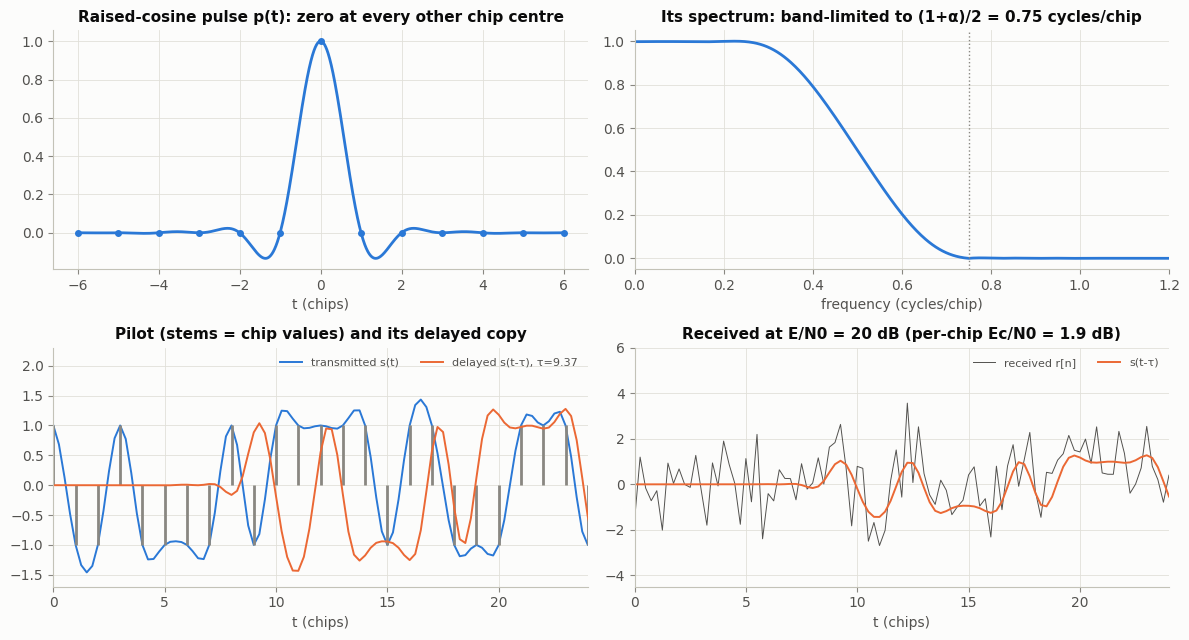

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
tp = np.linspace(-6, 6, 2001)
ax[0, 0].plot(tp, truncated_pulse(tp, cfg.rolloff, cfg.span), color=COLORS["mle"])
ax[0, 0].plot(k, rc_pulse(k, cfg.rolloff), "o", color=COLORS["mle"], ms=4)
ax[0, 0].set_title("Raised-cosine pulse p(t): zero at every other chip centre")
ax[0, 0].set_xlabel("t (chips)")

f = np.fft.rfftfreq(2 ** 16, d=tp[1] - tp[0])
P = np.abs(np.fft.rfft(truncated_pulse(tp, cfg.rolloff, cfg.span), n=2 ** 16))
ax[0, 1].plot(f, P / P.max(), color=COLORS["mle"])
ax[0, 1].axvline((1 + cfg.rolloff) / 2, color=MUTED, ls=":", lw=1)
ax[0, 1].set_xlim(0, 1.2)
ax[0, 1].set_title("Its spectrum: band-limited to (1+α)/2 = 0.75 cycles/chip")
ax[0, 1].set_xlabel("frequency (cycles/chip)")

tau = sc.tau_c + 0.37
t = sc.t
ax[1, 0].plot(t, sc.wave(t), color=COLORS["mle"], lw=1.4, label="transmitted s(t)")
ax[1, 0].stem(np.arange(sc.n_chips), sc.wave.chips, linefmt=MUTED, markerfmt=" ", basefmt=" ")
ax[1, 0].plot(t, sc.wave(t - tau), color=COLORS["dll"], lw=1.4, label=f"delayed s(t-τ), τ={tau:.2f}")
ax[1, 0].set_xlim(0, 24); ax[1, 0].set_ylim(-1.7, 2.3); ax[1, 0].legend(loc="upper right", fontsize=8, ncol=2)
ax[1, 0].set_title("Pilot (stems = chip values) and its delayed copy"); ax[1, 0].set_xlabel("t (chips)")

r = sc.observe(np.array([tau]), 10 ** 2.0, rng)[0]
ax[1, 1].plot(t, r, color=INK2, lw=0.7, label="received r[n]")
ax[1, 1].plot(t, sc.wave(t - tau), color=COLORS["dll"], lw=1.4, label="s(t-τ)")
ax[1, 1].set_xlim(0, 24); ax[1, 1].set_ylim(-4.5, 6); ax[1, 1].legend(loc="upper right", fontsize=8, ncol=2)
ax[1, 1].set_title("Received at E/N0 = 20 dB (per-chip Ec/N0 = 1.9 dB)"); ax[1, 1].set_xlabel("t (chips)")
fig.tight_layout(); fig.savefig(FIG + "s0_signal_model.png")

## 0.5 The autocorrelation — the single most important picture

Every estimator in this project compares the received signal with shifted copies of the pilot. How well a shift $h$
can be distinguished from the truth is governed by the **normalised autocorrelation**

$$ \rho(h)=\frac{\sum_n s(t_n)\,s(t_n-h)}{\sum_n s(t_n)^2}. $$

* the **width of the main lobe** sets the *local* accuracy → this is what the **CRLB** uses (its curvature at $h=0$);
* the **side-lobes and the prior width** set how easily a *distant wrong delay* can win → this is what the **ZZB** adds.

main-lobe half-width (first zero of rho): 1.34 chips; largest side-lobe beyond 1.5 chips: 0.13


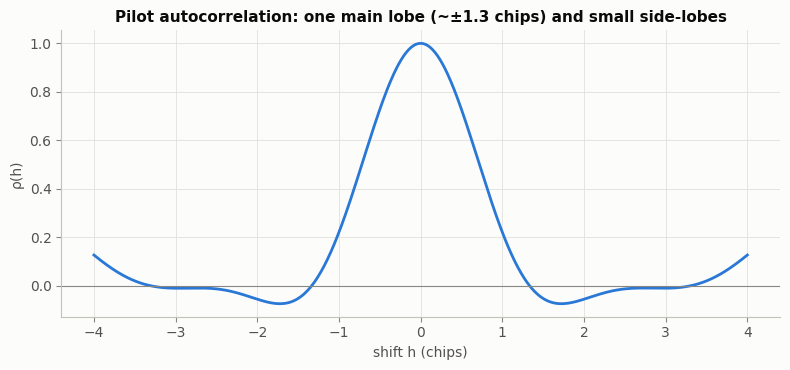

In [5]:
# rho(h) is symmetric; compute it for h >= 0 and mirror
hp = np.linspace(0, 4, 401)
rp = autocorrelation(sc, hp)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.concatenate([-hp[::-1], hp[1:]]), np.concatenate([rp[::-1], rp[1:]]), color=COLORS["mle"])
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xlabel("shift h (chips)"); ax.set_ylabel("ρ(h)")
ax.set_title("Pilot autocorrelation: one main lobe (~±1.3 chips) and small side-lobes")
fig.tight_layout(); fig.savefig(FIG + "s0_autocorrelation.png")
first_zero = hp[np.argmax(rp < 0)]
print(f"main-lobe half-width (first zero of rho): {first_zero:.2f} chips; largest side-lobe beyond 1.5 chips: "
      f"{np.max(np.abs(rp[hp > 1.5])):.2f}")

## 0.6 Notation used in all notebooks

| Symbol | Meaning |
|---|---|
| $\tau$, $\hat\tau$, $e=\hat\tau-\tau$ | true delay, estimate, error (chips) |
| $N_c=64$, $f_s=4$ | pilot length (chips), samples per chip |
| $\alpha=0.5$ | raised-cosine roll-off |
| $\beta^2$ | mean-square (Gabor) bandwidth of the waveform, 1/chip² (Sprint 3) |
| $E/N_0$ | total batch energy-to-noise ratio (dB on all plots) |
| $T_a=4$ | width of the uniform prior on $\tau$ (chips) |
| $\rho(h)$ | normalised autocorrelation of the pilot |
| $d=0.5$, $K$, $B_L$ | DLL early–late spacing, loop gain, loop noise bandwidth (Sprint 2) |

## 0.7 Key literature (verified citations)

| Topic | Reference |
|---|---|
| CRLB, MLE | S. M. Kay, *Fundamentals of Statistical Signal Processing, Vol. I*, 1993 (§3.11 range estimation, Ch. 7) |
| ZZB origin / improvement | Ziv & Zakai, IEEE T-IT 15(3), 1969; Chazan, Zakai & Ziv, IEEE T-IT 21(1), 1975 |
| ZZB general form (valley filling) | Bell, Steinberg, Ephraim & Van Trees, IEEE T-IT 43(2), 1997; Van Trees & Bell (eds.), *Bayesian Bounds*, 2007 |
| TDE bounds survey | Sadler & Kozick, IEEE SAM 2006 |
| ZZB vs MLE for delay | Mallat et al., arXiv:1405.4645 / 1405.4647 (2014); Xu, Baggeroer & Richmond, IEEE T-SP 52(12), 2004 |
| DLL theory | Kaplan & Hegarty (eds.), *Understanding GPS/GNSS*, 3rd ed., 2017; Betz & Kolodziejski, IEEE T-AES 45(4), 2009 |
| DLL loss of lock | Holmes & Biederman, IEEE T-COM 26(11), 1978 |

## 0.8 What this gives the next sprint
A fully specified, checked model: we know exactly what $\tau$, the noise and the SNR mean, and we have seen the
autocorrelation that will govern both the local (CRLB) and global (ZZB) behaviour. Sprint 1 builds the first estimator
on top of it.